### **Импорт библиотек**

In [1]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import root_mean_squared_error, mean_squared_error, mean_absolute_error, r2_score
from tensorflow import keras
from keras import layers
import matplotlib.pyplot as plt

2025-10-25 17:32:40.831138: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-10-25 17:32:40.872814: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-10-25 17:32:44.284747: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### **Импорт датасета**

In [3]:
df_train = pd.read_csv('./train.csv')
df_test = pd.read_csv('./test.csv')

### **EDA**

Тренировочный сет

In [4]:
df_train.head()

,ID,y,X0,X1,X2,X3,X4,X5,X6,X8,...,X375,X376,X377,X378,X379,X380,X382,X383,X384,X385
0,0,130.81,k,v,at,a,d,u,j,o,...,0,0,1,0,0,0,0,0,0,0
1,6,88.53,k,t,av,e,d,y,l,o,...,1,0,0,0,0,0,0,0,0,0
2,7,76.26,az,w,n,c,d,x,j,x,...,0,0,0,0,0,0,1,0,0,0
3,9,80.62,az,t,n,f,d,x,l,e,...,0,0,0,0,0,0,0,0,0,0
4,13,78.02,az,v,n,f,d,h,d,n,...,0,0,0,0,0,0,0,0,0,0


In [5]:
df_train.tail()

,ID,y,X0,X1,X2,X3,X4,X5,X6,X8,...,X375,X376,X377,X378,X379,X380,X382,X383,X384,X385
4204,8405,107.39,ak,s,as,c,d,aa,d,q,...,1,0,0,0,0,0,0,0,0,0
4205,8406,108.77,j,o,t,d,d,aa,h,h,...,0,1,0,0,0,0,0,0,0,0
4206,8412,109.22,ak,v,r,a,d,aa,g,e,...,0,0,1,0,0,0,0,0,0,0
4207,8415,87.48,al,r,e,f,d,aa,l,u,...,0,0,0,0,0,0,0,0,0,0
4208,8417,110.85,z,r,ae,c,d,aa,g,w,...,1,0,0,0,0,0,0,0,0,0


In [6]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4209 entries, 0 to 4208
Columns: 378 entries, ID to X385
dtypes: float64(1), int64(369), object(8)
memory usage: 12.1+ MB


In [7]:
df_train.describe()

,ID,y,X10,X11,X12,X13,X14,X15,X16,X17,...,X375,X376,X377,X378,X379,X380,X382,X383,X384,X385
count,4209.000000,4209.000000,4209.000000,4209.0,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,...,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000
mean,4205.960798,100.669318,0.013305,0.0,0.075077,0.057971,0.428130,0.000475,0.002613,0.007603,...,0.318841,0.057258,0.314802,0.020670,0.009503,0.008078,0.007603,0.001663,0.000475,0.001426
std,2437.608688,12.679381,0.114590,0.0,0.263547,0.233716,0.494867,0.021796,0.051061,0.086872,...,0.466082,0.232363,0.464492,0.142294,0.097033,0.089524,0.086872,0.040752,0.021796,0.037734
min,0.000000,72.110000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2095.000000,90.820000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4220.000000,99.150000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,6314.000000,109.010000,0.000000,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,8417.000000,265.320000,1.000000,0.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [8]:
df_train.shape

(4209, 378)

Тестовый датасет

In [9]:
df_test.head()

,ID,X0,X1,X2,X3,X4,X5,X6,X8,X10,...,X375,X376,X377,X378,X379,X380,X382,X383,X384,X385
0,1,az,v,n,f,d,t,a,w,0,...,0,0,0,1,0,0,0,0,0,0
1,2,t,b,ai,a,d,b,g,y,0,...,0,0,1,0,0,0,0,0,0,0
2,3,az,v,as,f,d,a,j,j,0,...,0,0,0,1,0,0,0,0,0,0
3,4,az,l,n,f,d,z,l,n,0,...,0,0,0,1,0,0,0,0,0,0
4,5,w,s,as,c,d,y,i,m,0,...,1,0,0,0,0,0,0,0,0,0


In [10]:
df_test.tail()

,ID,X0,X1,X2,X3,X4,X5,X6,X8,X10,...,X375,X376,X377,X378,X379,X380,X382,X383,X384,X385
4204,8410,aj,h,as,f,d,aa,j,e,0,...,0,0,0,0,0,0,0,0,0,0
4205,8411,t,aa,ai,d,d,aa,j,y,0,...,0,1,0,0,0,0,0,0,0,0
4206,8413,y,v,as,f,d,aa,d,w,0,...,0,0,0,0,0,0,0,0,0,0
4207,8414,ak,v,as,a,d,aa,c,q,0,...,0,0,1,0,0,0,0,0,0,0
4208,8416,t,aa,ai,c,d,aa,g,r,0,...,1,0,0,0,0,0,0,0,0,0


In [11]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4209 entries, 0 to 4208
Columns: 377 entries, ID to X385
dtypes: int64(369), object(8)
memory usage: 12.1+ MB


In [12]:
df_test.describe()

,ID,X10,X11,X12,X13,X14,X15,X16,X17,X18,...,X375,X376,X377,X378,X379,X380,X382,X383,X384,X385
count,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,...,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000,4209.000000
mean,4211.039202,0.019007,0.000238,0.074364,0.061060,0.427893,0.000713,0.002613,0.008791,0.010216,...,0.325968,0.049656,0.311951,0.019244,0.011879,0.008078,0.008791,0.000475,0.000713,0.001663
std,2423.078926,0.136565,0.015414,0.262394,0.239468,0.494832,0.026691,0.051061,0.093357,0.100570,...,0.468791,0.217258,0.463345,0.137399,0.108356,0.089524,0.093357,0.021796,0.026691,0.040752
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2115.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,4202.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,6310.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,8416.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [13]:
df_test.shape

(4209, 377)

### **Преобразование данных**

Обработка пропущенных значений

In [14]:
for col in df_train.columns:
  if df_train[col].isnull().sum():
    print(f'{col}')

for col in df_test.columns:
  if df_test[col].isnull().sum():
    print(f'{col}')
# Пропущенных значений нет

Удаление дубликатов

In [15]:
df_train.duplicated().sum()
df_test.duplicated().sum()

np.int64(0)

Удаление столбца ID

In [16]:
df_train.drop(['ID'], inplace=True, axis=1)
df_test.drop(['ID'], inplace=True, axis=1)

Кодирование категориальных признаков

In [17]:
X = df_train.drop(['y'], axis=1)
Y = df_train['y']
X_columns = X.columns
X

,X0,X1,X2,X3,X4,X5,X6,X8,X10,X11,...,X375,X376,X377,X378,X379,X380,X382,X383,X384,X385
0,k,v,at,a,d,u,j,o,0,0,...,0,0,1,0,0,0,0,0,0,0
1,k,t,av,e,d,y,l,o,0,0,...,1,0,0,0,0,0,0,0,0,0
2,az,w,n,c,d,x,j,x,0,0,...,0,0,0,0,0,0,1,0,0,0
3,az,t,n,f,d,x,l,e,0,0,...,0,0,0,0,0,0,0,0,0,0
4,az,v,n,f,d,h,d,n,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4204,ak,s,as,c,d,aa,d,q,0,0,...,1,0,0,0,0,0,0,0,0,0
4205,j,o,t,d,d,aa,h,h,0,0,...,0,1,0,0,0,0,0,0,0,0
4206,ak,v,r,a,d,aa,g,e,0,0,...,0,0,1,0,0,0,0,0,0,0
4207,al,r,e,f,d,aa,l,u,0,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:
encoder = OneHotEncoder(sparse_output=False)
categorical_columns = X.select_dtypes(include=['object']).columns.tolist()
encoded_features = encoder.fit_transform(X[categorical_columns])
encoded_features = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_columns))

X.drop(categorical_columns, inplace=True, axis=1)
X = pd.concat([X, encoded_features], axis=1)

In [19]:
X

,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,...,X8_p,X8_q,X8_r,X8_s,X8_t,X8_u,X8_v,X8_w,X8_x,X8_y
0,0,0,0,1,0,0,0,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0,0,0,0,0,0,0,0,1,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,0,0,0,0,0,0,1,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4204,0,0,0,0,1,0,0,0,0,0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4205,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4206,0,0,1,1,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4207,0,0,0,0,1,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


### **Тренировка сети**

Разбивка выборки

In [21]:
import mlflow

In [22]:
mlflow.set_tracking_uri("http://127.0.0.1:5000/")

In [23]:
from mlflow.keras import autolog

In [39]:
autolog(log_models=False,log_datasets=False)

In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

Инициализация модели

In [41]:
model1 = keras.Sequential([
        layers.Input(shape=(X.shape[1],)),

        layers.Dense(1024, activation='sigmoid'),
        layers.Dropout(0.6),

        # layers.Dense(512, activation='relu'),
        # layers.BatchNormalization(),
        # layers.Dropout(0.5),

        # layers.Dense(256, activation='relu'),
        # layers.BatchNormalization(),
        # layers.Dropout(0.4),

        layers.Dense(128, activation='sigmoid'),
        layers.Dropout(0.3),

        layers.Dense(64, activation='sigmoid'),
        layers.Dropout(0.2),

        layers.Dense(32, activation='relu'),
        layers.Dropout(0.1),

        layers.Dense(16, activation='relu'),
        layers.Dense(1)
    ])

In [118]:
# Модель использованая при подборе параметров и слоев. Игнорировать
# model2 = keras.Sequential([
#         layers.Input(shape=(X.shape[1],)),

#         layers.Dense(512, activation='relu'),
#         layers.BatchNormalization(),
#         layers.Dropout(0.5),

#         layers.Dense(256, activation='relu'),
#         layers.BatchNormalization(),
#         layers.Dropout(0.4),

#         layers.Dense(128, activation='relu'),
#         layers.BatchNormalization(),
#         layers.Dropout(0.3),

#         layers.Dense(64, activation='relu'),
#         layers.BatchNormalization(),
#         layers.Dropout(0.2),

#         layers.Dense(32, activation='relu'),
#         layers.Dense(1)
#       ])

In [28]:
# Модель использованая при подборе параметров и слоев. Игнорировать
# model3 = keras.Sequential([
#         layers.Input(shape=(X.shape[1],)),
#         layers.Dense(256, activation='swish'),
#         layers.BatchNormalization(),
#         layers.Dropout(0.3),

#         layers.Dense(128, activation='swish'),
#         layers.BatchNormalization(),
#         layers.Dropout(0.2),

#         layers.Dense(64, activation='swish'),
#         layers.Dense(1)
# ])

Компиляция модели

In [42]:
model1.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001, beta_1=0.9, beta_2=0.999),
    loss='mse',
    metrics=['mae']
)

In [43]:
model1.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 1024)           │       577,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 719,617 (2.75 MB)

 Trainable params: 719,617 (2.75 MB)

 Non-trainable params: 0 (0.00 B)

Обучение модели

In [44]:
history = model1.fit(
    X_train, y_train,
    epochs=100,
    batch_size=64,
    validation_split=0.2,
    verbose=1)

2025/10/25 18:22:30 INFO mlflow.utils.autologging_utils: Created MLflow autologging run with ID 'a5cde21499c1470fb3117763ed2f10fc', which will track hyperparameters, performance metrics, model artifacts, and lineage information for the current keras workflow


Epoch 1/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 8883.7520 - mae: 93.2804 - val_loss: 7017.6597 - val_mae: 82.8295
Epoch 2/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 4629.9751 - mae: 65.6453 - val_loss: 1769.3285 - val_mae: 40.1545
Epoch 3/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 665.1934 - mae: 20.6526 - val_loss: 158.4002 - val_mae: 10.1326
Epoch 4/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 254.8616 - mae: 12.5073 - val_loss: 157.4911 - val_mae: 9.8738
Epoch 5/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 259.0739 - mae: 12.5209 - val_loss: 157.4951 - val_mae: 9.8736
Epoch 6/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 259.9902 - mae: 12.5944 - val_loss: 157.4964 - val_mae: 9.8736
Epoch 7/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 265.3518 - mae: 12.6655 - val_loss: 158.1933 - val_mae: 9.8611
Epoch 8/100
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 262.5883 - mae: 12.6408 - val_loss: 157.3054 - val_mae: 9.8812
Epoch 9/1

In [45]:
train_loss, train_mae = model1.evaluate(X_train, y_train, verbose=0)
test_loss, test_mae = model1.evaluate(X_test, y_test, verbose=0)

print(f"Training MSE: {train_loss:.4f}, Training MAE: {train_mae:.4f}")
print(f"Test MSE: {test_loss:.4f}, Test MAE: {test_mae:.4f}")


Training MSE: 65.6338, Training MAE: 4.6764
Test MSE: 73.4555, Test MAE: 5.3362


Предсказание

In [46]:
y_pred = model1.predict(X_test).flatten()

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = root_mean_squared_error(y_test, y_pred)

print(f"Prediction RMSE: {rmse:.4f}")
print(f"Prediction MSE: {mse:.4f}")
print(f"Prediction R² Score: {r2:.4f}")
print(f"Prediction MAE: {mae:.4f}")

27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Prediction RMSE: 8.5706
Prediction MSE: 73.4555
Prediction R² Score: 0.5281
Prediction MAE: 5.3362


In [47]:
with mlflow.start_run(run_id="a5cde21499c1470fb3117763ed2f10fc", experiment_id="0") as run:
    mlflow.log_metrics(
        {
            "Prediction RMSE": rmse,
            "Prediction MSE": mse,
            "Prediction R² Score": r2,
            "Prediction MAE": mae,
        }
    )

🏃 View run auspicious-whale-23 at: http://127.0.0.1:5000/#/experiments/0/runs/a5cde21499c1470fb3117763ed2f10fc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/0


### **Resediual plot**

In [48]:
predictions = pd.DataFrame({'True': y_test, 'Pred': y_pred})
predictions

,True,Pred
1073,97.94,90.160301
144,96.41,90.204193
2380,105.83,116.635841
184,79.09,75.685211
2587,108.69,108.261711
...,...,...
657,113.68,109.446655
3975,88.85,89.950508
907,89.60,94.127876
3597,89.23,92.268562


Text(0, 0.5, 'Отклонения предсказанных значений')

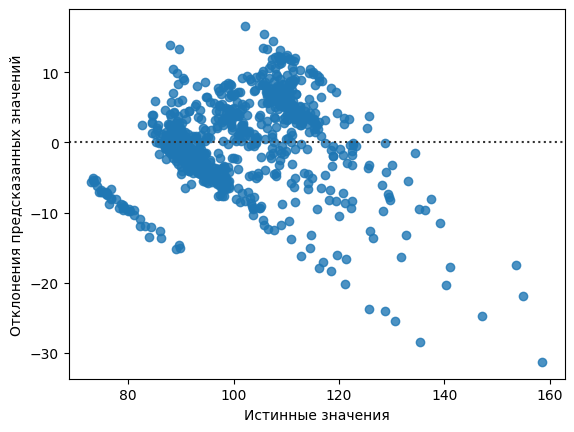

In [60]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.residplot(x='True', y='Pred', data=predictions,ax=ax)
plt.xlabel("Истинные значения")
plt.ylabel("Отклонения предсказанных значений")
plt.tight_layout()
plt.close(fig)

In [ ]:
with mlflow.start_run(run_id="a5cde21499c1470fb3117763ed2f10fc", experiment_id="0") as run:
    mlflow.log_figure(fig, "resid_plot.png")

### **Графики потерь и метрик во время обучения**

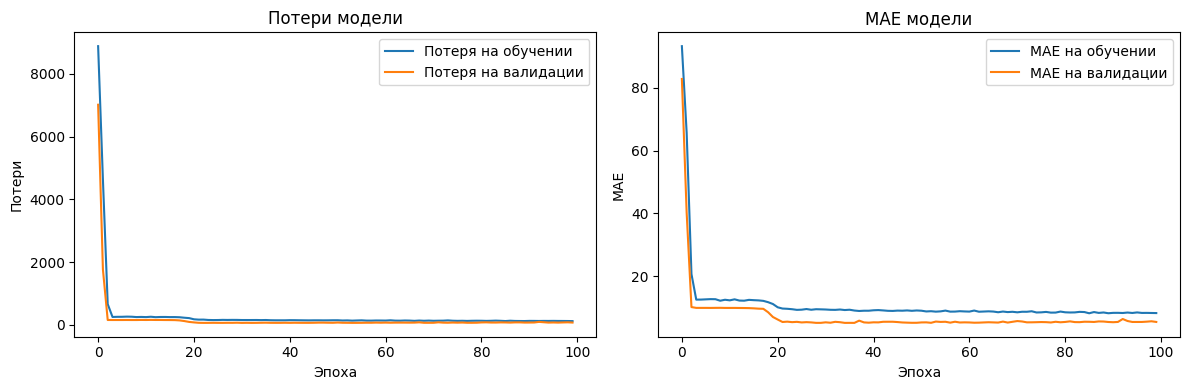

In [65]:
fig = plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Потеря на обучении')
plt.plot(history.history['val_loss'], label='Потеря на валидации')
plt.title('Потери модели')
plt.ylabel('Потери')
plt.xlabel('Эпоха')
plt.legend(loc='upper right')

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='MAE на обучении')
plt.plot(history.history['val_mae'], label='MAE на валидации')
plt.title('MAE модели')
plt.ylabel('MAE')
plt.xlabel('Эпоха')
plt.legend(loc='upper right')

plt.tight_layout()
plt.close(fig)

In [66]:
with mlflow.start_run(run_id="a5cde21499c1470fb3117763ed2f10fc", experiment_id="0") as run:
    mlflow.log_figure(fig, "train-steps.png")

🏃 View run auspicious-whale-23 at: http://127.0.0.1:5000/#/experiments/0/runs/a5cde21499c1470fb3117763ed2f10fc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/0
